In [5]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import torch
import torch.nn as nn
import os
import numpy as np

os.chdir("/Users/shanewarland/Desktop/transformer-from-scratch/notebooks")
os.getcwd()

'/Users/shanewarland/Desktop/transformer-from-scratch/notebooks'

Set seeds to ensure consistent runs

In [65]:
import random
import numpy as np
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

Create and porcess training data

In [66]:
from src.synthetic_data import generate_synthetic_dna_scramble_motif, generate_synthetic_dna_with_motif, create_combined_dataset

motif = "TATAAA"
scramble_motif = "AAATAT"
negatives = generate_synthetic_dna_scramble_motif(10000, 100, motif, scramble_motif)
positives = generate_synthetic_dna_with_motif(10000, 100, motif)
sequences, labels = create_combined_dataset(negatives, positives)
assert len(sequences) == 10000
assert len(labels) == 10000
assert sum(labels) == 5000
assert len(motif) == len(scramble_motif)

for seq, label in zip(sequences, labels):
    if label == 0:
        assert motif not in seq
    else:
        assert motif in seq

In [67]:
from sklearn.model_selection import train_test_split
from src.dataset import DNADataset
from torch.utils.data import DataLoader

X_train, X_val, y_train, y_val = train_test_split(sequences, labels, test_size = 0.2, stratify = labels, random_state = 42)

train_dataset = DNADataset(X_train, y_train)
val_dataset = DNADataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

Initiate the model

In [68]:
import torch
import torch.nn as nn
from src.dna_transformer import DNATransformer

model = DNATransformer(vocab_size=6,d_model=8,num_heads=2,d_ff=32,num_layers=3,max_len=101)


In [69]:
from src.training import train_val_model

#train_val_model(train_dataloader, validation_dataloader, model, num_epochs, lr = 1e-3)

history = train_val_model(train_loader, val_loader, model, num_epochs = 100, lr = 1e-3)

Epoch 1: train=0.6970, val=0.6963 val_acc=0.5000
Epoch 2: train=0.6941, val=0.6931 val_acc=0.5000
Epoch 3: train=0.6939, val=0.6932 val_acc=0.5000
Epoch 4: train=0.6943, val=0.6930 val_acc=0.4990
Epoch 5: train=0.6935, val=0.6934 val_acc=0.5000
Epoch 6: train=0.6933, val=0.6946 val_acc=0.5000
Epoch 7: train=0.6936, val=0.6953 val_acc=0.5000
Epoch 8: train=0.6936, val=0.6931 val_acc=0.5010
Epoch 9: train=0.6938, val=0.6932 val_acc=0.5000
Epoch 10: train=0.6936, val=0.6931 val_acc=0.5010
Epoch 11: train=0.6936, val=0.6948 val_acc=0.5000
Epoch 12: train=0.6936, val=0.6931 val_acc=0.4930
Epoch 13: train=0.6935, val=0.6931 val_acc=0.5105
Epoch 14: train=0.6937, val=0.6932 val_acc=0.5045
Epoch 15: train=0.6933, val=0.6933 val_acc=0.4945
Epoch 16: train=0.6933, val=0.6934 val_acc=0.5070
Epoch 17: train=0.6933, val=0.6933 val_acc=0.5080
Epoch 18: train=0.6934, val=0.6933 val_acc=0.4905
Epoch 19: train=0.6927, val=0.6942 val_acc=0.5055
Epoch 20: train=0.6927, val=0.6936 val_acc=0.4955
Epoch 21:

Ok now lets create a training validation plot.

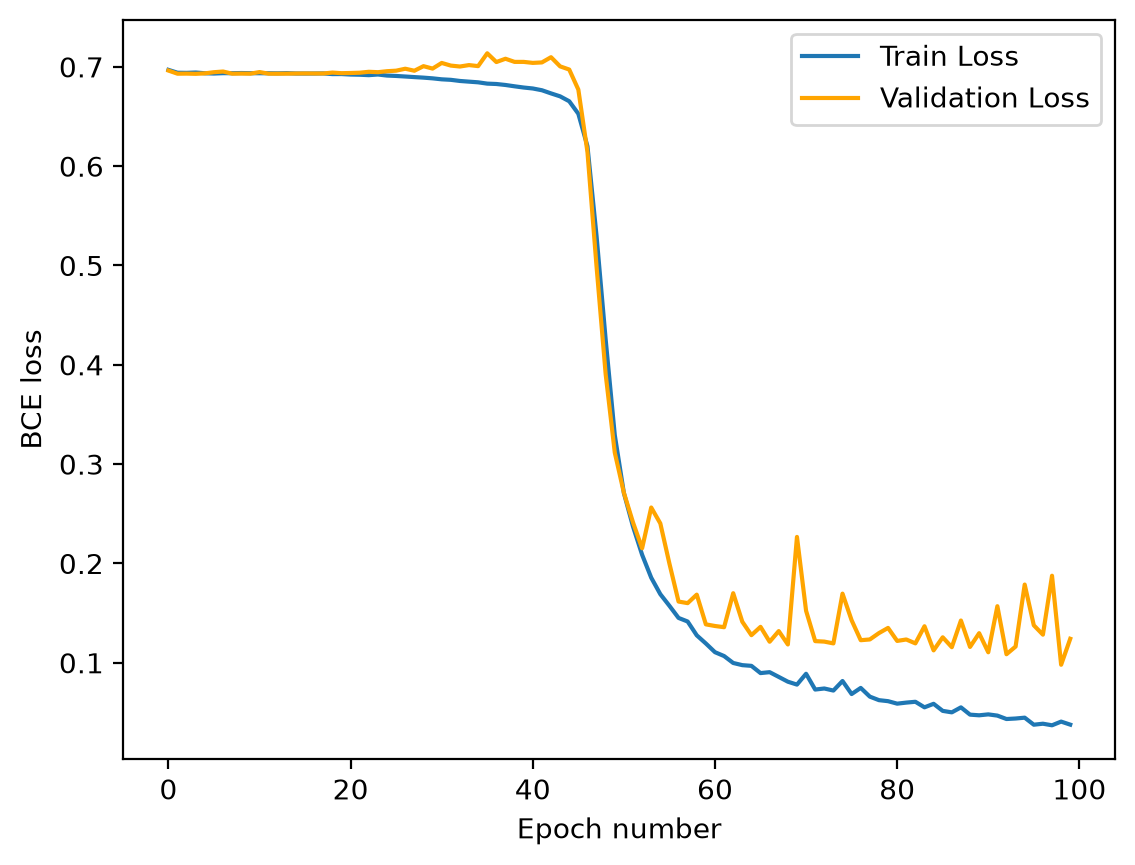

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['validation_loss'], color = 'orange', label='Validation Loss')
plt.xlabel('Epoch number')
plt.ylabel('BCE loss')
plt.legend()
#plt.savefig(f"../figures/train_validation_plot.png", dpi=300, bbox_inches="tight")
plt.show()


Here is the training plot of the history. The model trained for about 40 epochs before it began decreasing loss. The validation and loss curves separate around epoch 55, suggesting using early stopping would be beneficial. 

Save the model for future generations. 

In [ ]:
#torch.save(model.state_dict(), "../models/relative_transformer_motif.pt")

Ok great looks like the model is actually working now and achieves 99.9% accuracy.

Now let's understand how the model learns what the relative-position heads learned.

In [71]:
import pandas as pd 
for layer in model.encoder.layers:
    with torch.no_grad():
        bias = layer.attention.relative_bias.weight
        max_len = 101
        distance_index = list(range(-10 + (max_len - 1), 10 + 1 + (max_len - 1)))
        motif_biases = bias[distance_index]
        distance_val = list(range(-10, 11))
        print(motif_biases.shape)
        df = pd.DataFrame( motif_biases.numpy(), index = distance_val)
        print(df)


torch.Size([21, 2])
            0         1
-10 -0.582411 -0.245877
-9   1.328403  1.021489
-8  -0.129161  0.307644
-7  -0.600578 -1.159375
-6   0.811584  0.440065
-5  -1.579309  1.000907
-4  -2.474372  2.413483
-3  -3.739196  2.971085
-2  -3.413784  2.503570
-1  -2.020812  3.297657
 0   0.779457 -0.569033
 1   0.107837  1.561555
 2   0.192724 -0.885712
 3   0.936986 -0.305063
 4  -0.485349 -0.489225
 5  -0.770693 -2.247812
 6  -0.312306 -0.071878
 7   0.167050  0.060527
 8  -0.704503 -0.613423
 9   0.797719  0.198235
 10  0.420264  0.295490
torch.Size([21, 2])
            0         1
-10 -2.047721 -0.432333
-9  -0.755462  0.780357
-8   1.352805 -0.136396
-7   0.218833 -2.431819
-6   1.301425  0.542125
-5   2.042279  1.170526
-4   2.633195 -0.501265
-3   0.760715 -0.962752
-2  -2.962475 -0.962271
-1   0.414363  0.189266
 0   0.257139 -0.760119
 1   0.745266 -1.671109
 2  -1.054602 -0.557807
 3   0.117625 -2.262851
 4   0.338023 -0.994546
 5  -0.329798  0.474182
 6   0.767602  1.101090


Lets get the whole range and not just -10:10

             0         1
-100 -0.940790  0.052115
-99   0.268903  0.049652
-98  -0.126590  0.422398
-97   0.019408 -0.297422
-96  -1.682698 -0.615627
...        ...       ...
 96  -1.197216  1.550391
 97   0.434167 -0.025591
 98   0.543215 -0.083726
 99   1.506541  0.325150
 100  0.772656  1.125101

[201 rows x 2 columns]
             0         1
-100 -0.095790  0.171496
-99   1.268676  1.234569
-98   1.381017  1.141029
-97   0.714705 -0.012258
-96  -0.733633  0.255779
...        ...       ...
 96  -0.125860 -0.726738
 97  -1.850145  0.704629
 98  -0.252602  0.929001
 99  -1.217696  1.109069
 100  1.012046  1.220478

[201 rows x 2 columns]
             0         1
-100 -1.721956 -0.448020
-99   0.336282  0.649143
-98  -0.098580 -0.035178
-97   0.140634  0.416516
-96  -0.051014  0.475722
...        ...       ...
 96   0.296054  0.264744
 97   0.597664 -0.687111
 98  -1.609364  1.667792
 99  -1.021090 -0.921914
 100  0.295439  0.012082

[201 rows x 2 columns]


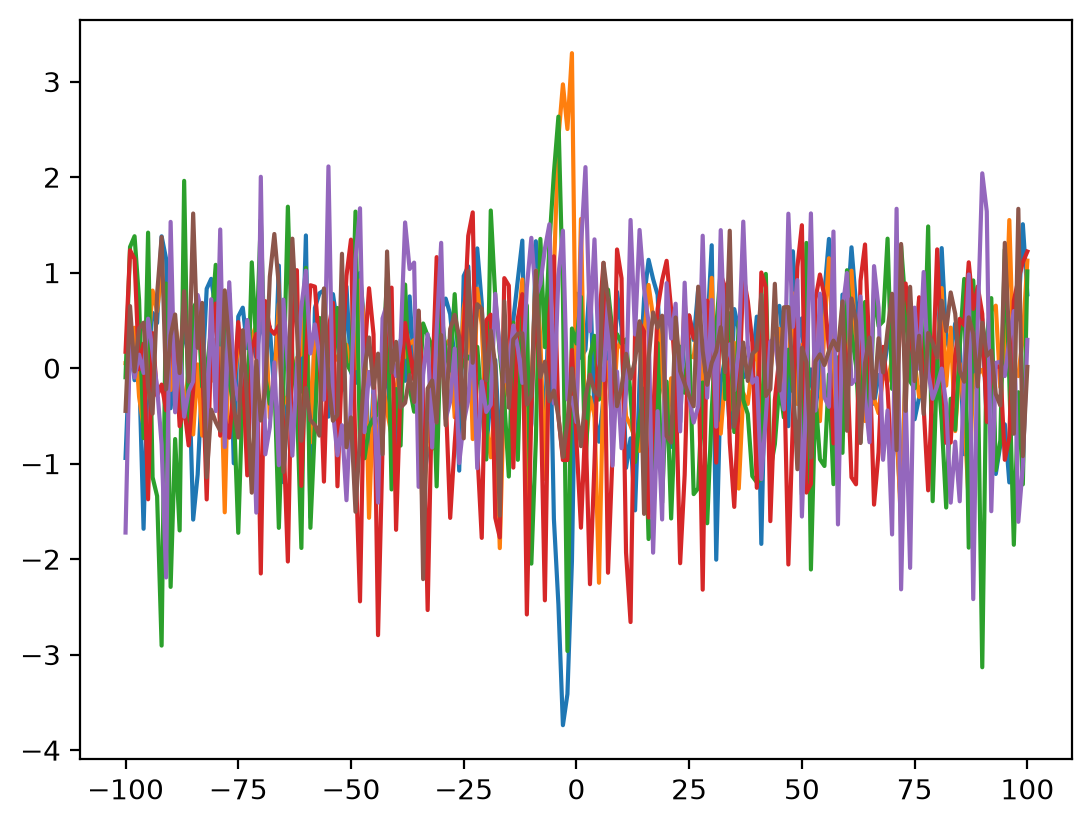

In [72]:
import pandas as pd 
import matplotlib.pyplot as plt
for layer in model.encoder.layers:
    with torch.no_grad():
        bias = layer.attention.relative_bias.weight
        max_len = 101
        distances = range(-(max_len - 1), max_len)
        bias = layer.attention.relative_bias.weight.detach().numpy()
        df = pd.DataFrame( bias, index = distances)
        print(df)
        plt.plot(distances, bias[:, 0])
        plt.plot(distances, bias[:, 1])
plt.show()

Looks like some layer/head activates strongly at local sequences +-5.

Lets feed a positive sequence into the model and find which nucelotides in motif (TATAAA) acted as the query

In [75]:
positive_sequence = generate_synthetic_dna_with_motif(1, 100, motif)
motif_start = positive_sequence[0].find("TATAAA")
print(motif_start)

12


In [76]:
try_dataset = DNADataset(positive_sequence , [1])
try_loader = DataLoader(try_dataset, batch_size=32, shuffle=True)

X, y = next(iter(try_loader))

model.eval()

with torch.no_grad():
    logits, layer_weights = model(X)

for layer in layer_weights:
    attention_for_query = layer[0, 0, 52, 52:58]
    print(attention_for_query)
        


tensor([0.0165, 0.0092, 0.0095, 0.0193, 0.0050, 0.0038])
tensor([0.0065, 0.0094, 0.0019, 0.0056, 0.0086, 0.0054])
tensor([0.0054, 0.0068, 0.0784, 0.0160, 0.0332, 0.0063])


Lets create a negative seqeunce by replaceing the positive motif string 'TATAAA' with 'AAATAT'

In [77]:
negative_sequence = [positive_sequence[0].replace("TATAAA", "AAATAT")]
negative_sequence[0].find("AAATAT")

try_dataset = DNADataset(negative_sequence , [0])
try_loader = DataLoader(try_dataset, batch_size=32, shuffle=True)

X, y = next(iter(try_loader))

model.eval()

with torch.no_grad():
    logits, neg_layer_weights = model(X)

for layer in neg_layer_weights:
    attention_for_query = layer[0, 0, 52, 52:58]
    print(attention_for_query)

tensor([0.0165, 0.0092, 0.0095, 0.0193, 0.0050, 0.0038])
tensor([0.0066, 0.0100, 0.0019, 0.0058, 0.0087, 0.0053])
tensor([0.0042, 0.0229, 0.0597, 0.0106, 0.0244, 0.0059])


Ok great. So in the positive sequence, the query 52 (first T) has 0.4115 attention on key 54 (second T). In the negative control, the attention of query 52 on key 54 is now 0.0026. The attention was 160-fold greater for positive example, and the relative distance bias was the saem in both cases (+2).

This was just one instance however. Lets test is for 100 examples.

In [78]:
positive_sequence = []
for i in range(100):
    while True:
        next_pos_seq = generate_synthetic_dna_with_motif(1, 100, motif)[0]
        if 'AAATAT' not in next_pos_seq:
            positive_sequence.append(next_pos_seq)
            break

pos_motif_start_list = [sequence.find("TATAAA") for sequence in positive_sequence]
print(pos_motif_start_list)
negative_sequence = [sequence.replace("TATAAA", "AAATAT") for sequence in positive_sequence]
neg_motif_start_list = [sequence.find("AAATAT") for sequence in negative_sequence]
assert neg_motif_start_list == pos_motif_start_list
motif_start_list = neg_motif_start_list

[25, 36, 34, 59, 15, 34, 43, 52, 52, 58, 62, 25, 45, 71, 35, 59, 21, 26, 62, 72, 94, 69, 66, 75, 36, 77, 79, 84, 85, 63, 88, 78, 49, 93, 77, 37, 23, 55, 27, 25, 62, 49, 61, 26, 39, 86, 74, 57, 79, 10, 73, 70, 64, 3, 82, 16, 84, 17, 8, 43, 34, 25, 66, 87, 75, 82, 26, 37, 31, 70, 25, 91, 6, 69, 92, 83, 72, 89, 90, 71, 34, 2, 65, 8, 84, 61, 21, 81, 50, 79, 87, 24, 67, 76, 76, 16, 93, 13, 51, 43]


In [79]:
positive_dataset = DNADataset(positive_sequence , 100*[1])
positive_loader = DataLoader(positive_dataset , batch_size=32, shuffle=True)
negative_dataset = DNADataset(negative_sequence , 100*[0])
negative_loader = DataLoader(negative_dataset , batch_size=32, shuffle=True)

In [80]:
model.eval()

pos_layer_list = []
neg_layer_list = []
for i in range(len(motif_start_list)):

    X, y = positive_dataset[i]
    X = X.unsqueeze(0)
    with torch.no_grad():
        logits, pos_layer_weights = model(X)
    
    layer_list = []

    for layer in pos_layer_weights:
        attention_for_query = layer[0, 0, motif_start_list[i]+1, motif_start_list[i]+3]
        layer_list.append(attention_for_query)

    pos_layer_list.append(layer_list)

    X, y = negative_dataset[i]
    X = X.unsqueeze(0)
    with torch.no_grad():
        logits, neg_layer_weights = model(X)

    layer_list = []
    
    for layer in neg_layer_weights:
        attention_for_query = layer[0, 0, motif_start_list[i]+1, motif_start_list[i]+3]
        layer_list.append(attention_for_query)
        
    neg_layer_list.append(layer_list)

len(pos_layer_list)

100

In [81]:
raw_data = [[t.numpy() for t in list] for list in pos_layer_list]
pos_df = pd.DataFrame(raw_data, columns=['Layer1', 'Layer2', 'Layer3'])
raw_data = [[t.numpy() for t in list] for list in neg_layer_list]
neg_df = pd.DataFrame(raw_data, columns=['Layer1', 'Layer2', 'Layer3'])
print(pos_df.head())
print(neg_df.head())
print(pos_df['Layer3'].mean())
print(neg_df['Layer3'].mean())

         Layer1        Layer2       Layer3
0   0.008747981  0.0023773042    0.0867482
1   0.008628148  0.0023439045   0.10067714
2   0.008783167  0.0020601884  0.078784995
3   0.008921746  0.0021255554   0.04507001
4  0.0089810155  0.0020991636   0.07554554
        Layer1        Layer2       Layer3
0  0.009243896  0.0051116766  0.035449646
1  0.009099877  0.0024324534   0.04485844
2  0.009234014  0.0020401399  0.036271725
3  0.009426572  0.0017961352   0.04074231
4  0.009422563  0.0017676468  0.048272632
0.06267508506774902
0.03974373817443848


Layer 3, head 0 shows strong motif-dependent attention from the first to the third motif position in positive sequences.

Ok better text is to look at the 6 × 6 motif attention matrix for positives versus matched negatives. I just need to expand the for loops. 

In [82]:
model.eval()

pos_layer_list = []
neg_layer_list = []
motif_size = 6
for i in range(len(motif_start_list)):

    X, y = positive_dataset[i]
    X = X.unsqueeze(0)
    with torch.no_grad():
        logits, pos_layer_weights = model(X)
    
    layer_list = []
    motif_start_coor = motif_start_list[i]+1
    motif_end_coor = motif_start_coor+6
    for layer in pos_layer_weights:
        attention_for_query = layer[0, 0, motif_start_coor:motif_end_coor, motif_start_coor:motif_end_coor]
        layer_list.append(attention_for_query)

    pos_layer_list.append(layer_list)

    X, y = negative_dataset[i]
    X = X.unsqueeze(0)
    with torch.no_grad():
        logits, neg_layer_weights = model(X)

    layer_list = []
    motif_start_coor = motif_start_list[i]+1
    motif_end_coor = motif_start_coor+6
    motif_range = range(motif_start_coor,motif_end_coor)
    
    for layer in neg_layer_weights:
        attention_for_query = layer[0, 0, motif_start_coor:motif_end_coor, motif_start_coor:motif_end_coor]
        layer_list.append(attention_for_query)
        
    neg_layer_list.append(layer_list)

len(pos_layer_list)

100

In [83]:
pos_tensor = torch.stack([torch.stack(inner_list, dim=0) for inner_list in pos_layer_list], dim=0)
neg_tensor = torch.stack([torch.stack(inner_list, dim = 0) for inner_list in neg_layer_list])
neg_tensor.shape

torch.Size([100, 3, 6, 6])

In [84]:
delta_tensor = (pos_tensor - neg_tensor).mean(dim=0)
print(delta_tensor.shape)
print(delta_tensor)

torch.Size([3, 6, 6])
tensor([[[-8.7827e-04,  1.3331e-04, -4.8844e-04,  6.6678e-04,  7.3660e-05,
           1.2088e-04],
         [-1.8847e-05, -1.3550e-06, -1.5838e-04,  1.7092e-04, -1.5862e-06,
           8.6757e-05],
         [-1.3361e-05,  1.5359e-05, -8.8501e-04,  2.8662e-04,  1.4050e-04,
           6.5675e-04],
         [-6.3343e-06, -4.1221e-06, -3.5317e-05,  8.6415e-04, -1.3949e-04,
           4.8059e-04],
         [-1.1977e-05, -2.9241e-08, -4.6812e-06,  1.8527e-05, -2.6817e-06,
           1.5569e-04],
         [-5.4161e-05, -1.0249e-05, -6.2468e-06,  1.3137e-05, -1.6131e-05,
           8.7017e-04]],

        [[ 1.2071e-03,  2.1428e-03, -2.1569e-04,  4.1309e-03,  1.9633e-02,
           1.2387e-02],
         [-5.6474e-03, -3.8425e-03, -8.1288e-03, -2.6902e-03,  3.7163e-03,
           3.1948e-03],
         [-1.8139e-04,  6.5441e-04,  8.1453e-03, -6.0360e-03,  3.6070e-03,
           7.0560e-03],
         [-1.9698e-02, -9.0460e-04, -2.3834e-02, -1.2667e-01, -5.7390e-02,
          

Ok now that we have wrangled these tensors into submission we can pick a layer and look at the 6×6 matrix as query-key relationships.

In [85]:
delta_df_list = []
for delta in delta_tensor:
    delta_df = pd.DataFrame(delta.numpy(), columns = ["T0", "A1", "T2", "A3", "A4", "A5"], index = ["T0", "A1", "T2", "A3", "A4", "A5"])
    delta_df_list.append(delta_df)
delta_df_list[2]

,T0,A1,T2,A3,A4,A5
T0,0.002368,0.000137,0.022931,0.001392,-0.008502,-0.000982
A1,0.001300,0.000457,0.007641,0.006222,-0.001893,-0.002093
T2,0.001659,0.000254,0.002523,0.000977,-0.016278,-0.002431
A3,0.002897,-0.000459,0.000659,-0.000958,-0.008408,-0.028036
A4,0.003460,0.003452,0.001158,0.001368,-0.000566,0.000419
A5,0.000546,-0.000606,0.002808,-0.001917,-0.001928,-0.002662


The model learned a contextual representation of the motif in which the second T becomes an important attention target. Lets create a heatmap to visualize.

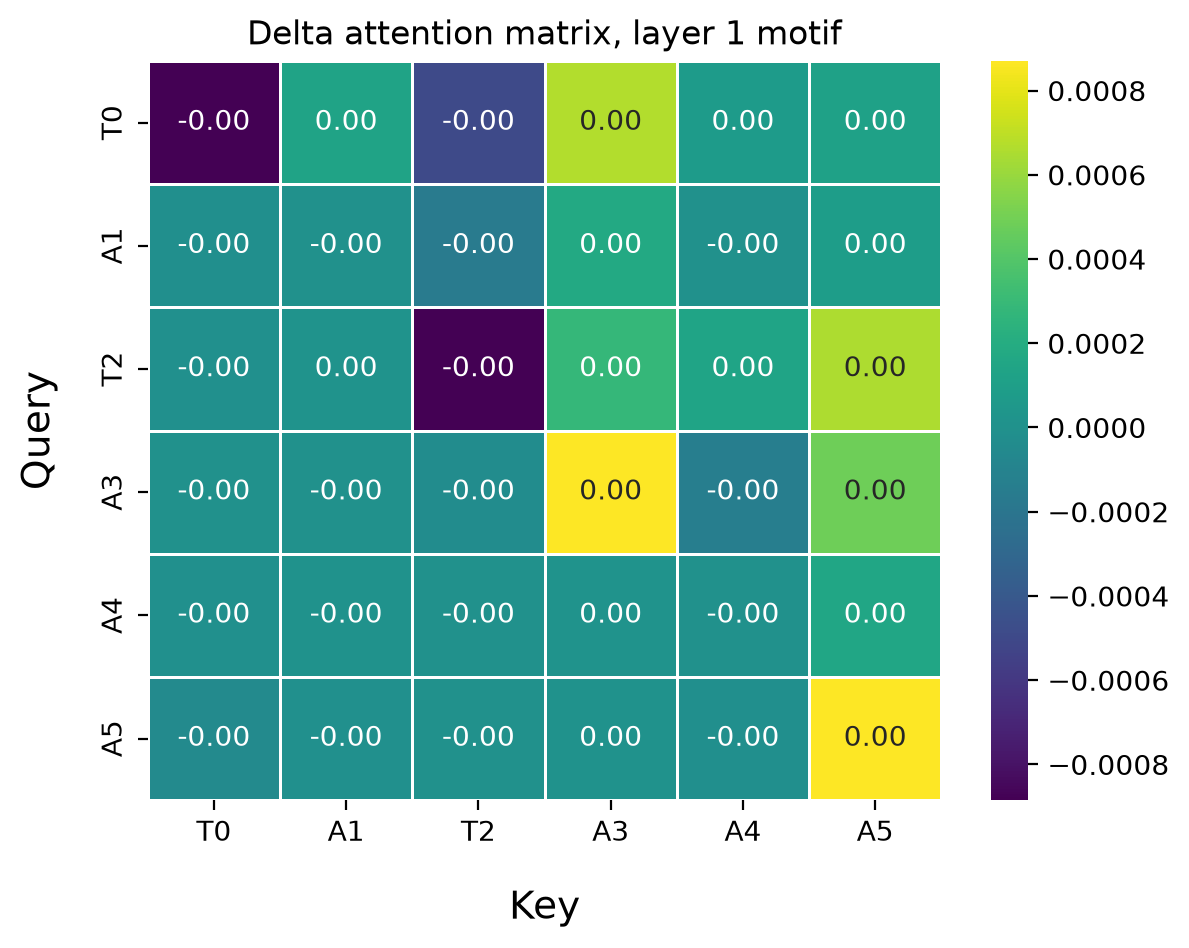

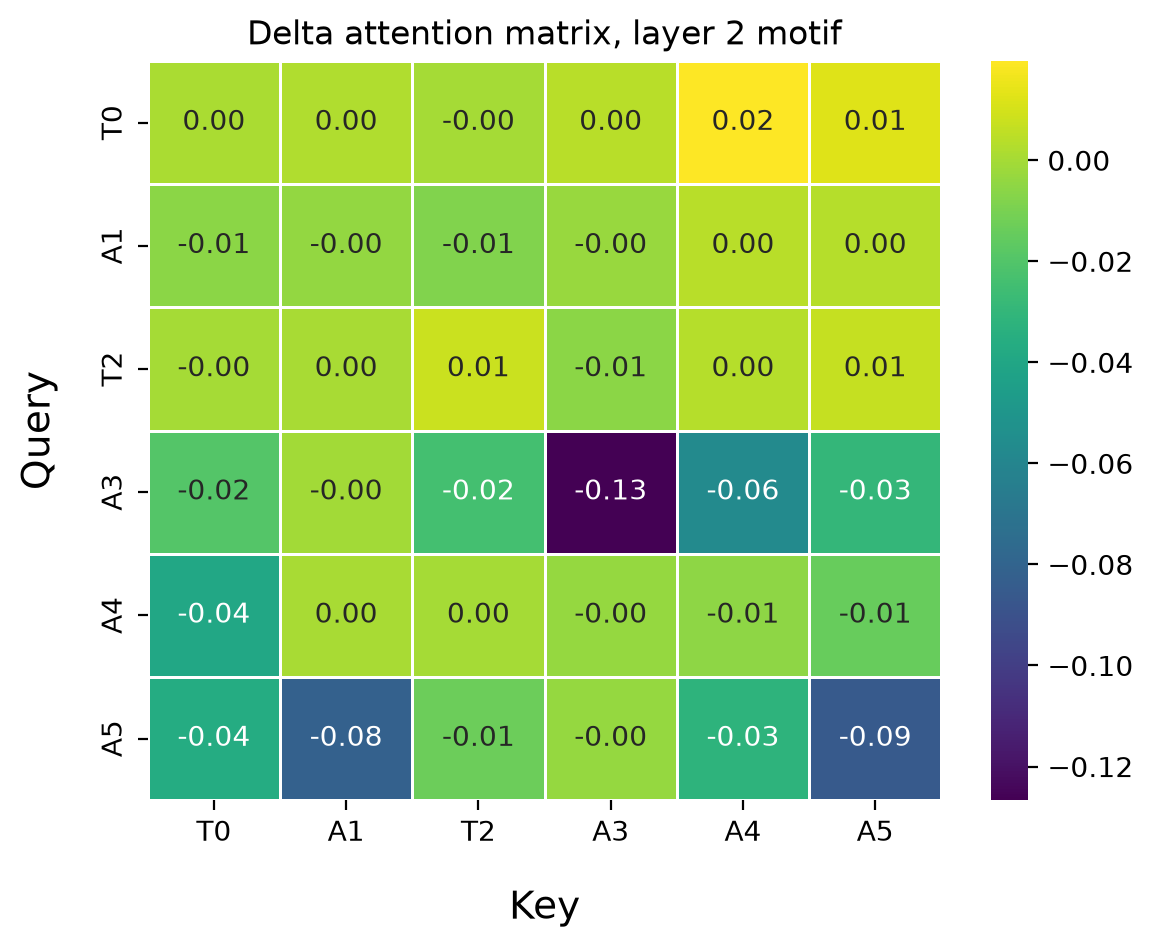

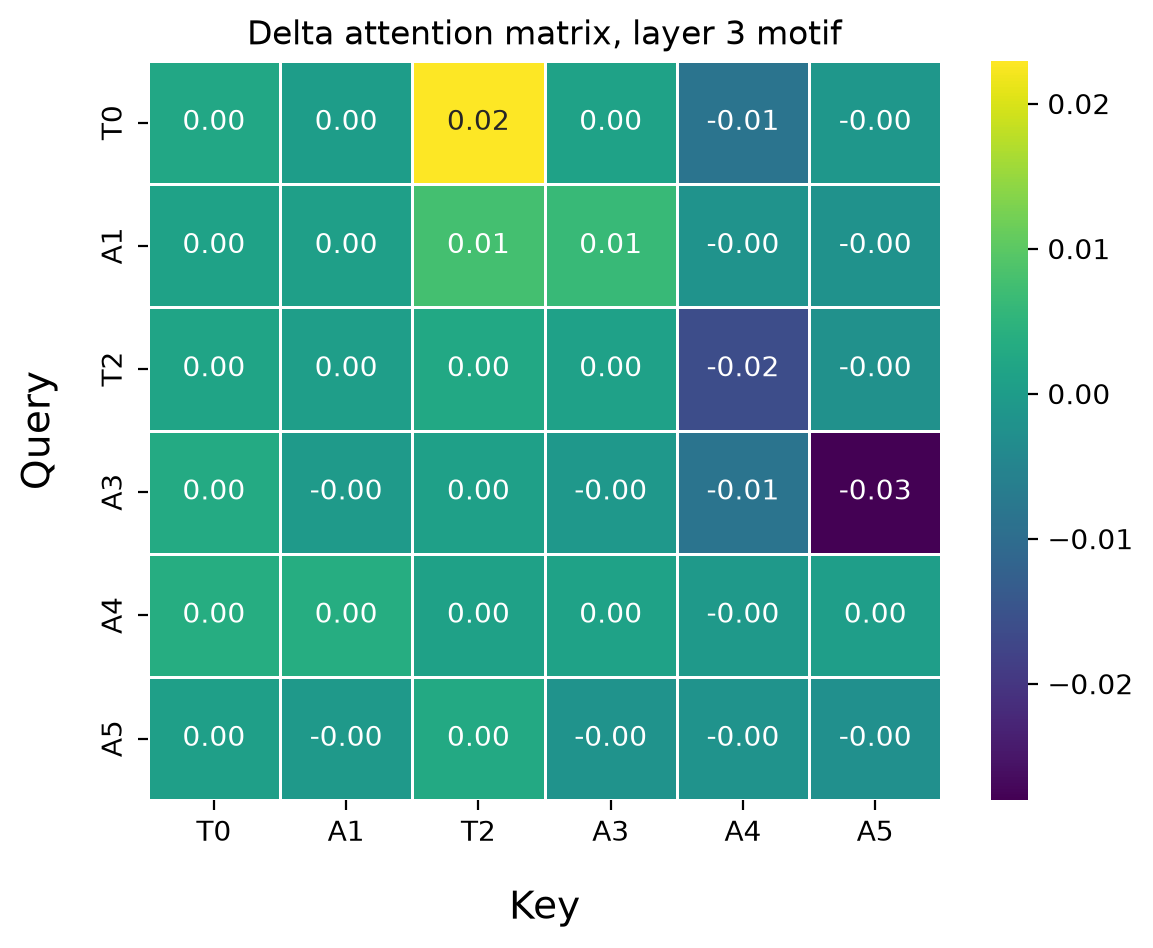

In [87]:
import seaborn as sns
for i, tensor_df in enumerate(delta_df_list):
    sns.heatmap(
    tensor_df,
    annot=True,  
    fmt=".2f",  
    cmap="viridis",  
    linewidths=0.5, 
)

    plt.title(f"Delta attention matrix, layer {i + 1} motif")
    plot_title = f"V2_Atention_layer_{i+1}_heatmap.png"
    plt.ylabel("Query", fontsize=14, labelpad=15)  
    plt.xlabel("Key", fontsize=14, labelpad=15)

    plt.savefig(f"../figures/{plot_title}", dpi=300, bbox_inches="tight")
    plt.show()


Perfect, layer 3 suggests that the transformer is using the second T in the motif as a way to identify the sequence. Primairly the attention from the first T on the second T is much greater for the acutaly motif compared the the A to A attention in the scrambled negative motif AAATAT. 

UPDATE: I reran the model from scratch and it learned a new way of identifying the motif. This way doesn't have the same satisfying focus on the two Ts in the third layer of the first head but oh well. This model performs equally well regardless.